In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style for charts
sns.set_style("whitegrid")

In [6]:
df1 = pd.read_csv("/Country-Series - Metadata.csv", encoding="cp1252")
df2 = pd.read_csv("/IDS_ALLCountries_Data.csv", encoding="cp1252")
df3 = pd.read_csv("/IDS_CountryMetaData.csv", encoding="cp1252")
df4 = pd.read_csv("/IDS_FootNoteMetaData.csv", encoding="cp1252")
df5 = pd.read_csv("/IDS_SeriesMetaData.csv", encoding="cp1252")

print("df1 (Country-Series):", df1.shape)
print("df2 (All Countries Data):", df2.shape)
print("df3 (Country Metadata):", df3.shape)
print("df4 (Footnote Metadata):", df4.shape)
print("df5 (Series Metadata):", df5.shape)

df1 (Country-Series): (375, 4)
df2 (All Countries Data): (62983, 39)
df3 (Country Metadata): (134, 30)
df4 (Footnote Metadata): (2673, 5)
df5 (Series Metadata): (574, 12)


In [7]:
#Country-Series table
df1_clean = df1.copy()
df1_clean.columns = df1_clean.columns.str.strip().str.replace(' ', '_')   #Remove space, adding '_'

# Drop constant column
df1_clean.drop(columns=['Type'], inplace=True)  #it has the exact same constant value in every row

# Extract clean codes from parentheses
df1_clean['Country_Code'] = df1_clean['Country_Code'].str.extract(r'\(([^)]+)\)')[0].str.strip() #Regex to pull out only the clean code hidden inside parentheses
                                                                                                 #Ex:turning "Afghanistan (AFG)" into "AFG"
df1_clean['Series_Code'] = df1_clean['Series_Code'].str.extract(r'\(([^)]+)\)$')[0].str.strip()  #Same for series code

# Remove duplicates
df1_clean.drop_duplicates(inplace=True)

print("df1_clean shape:", df1_clean.shape)
print("Nulls:\n", df1_clean.isnull().sum())

df1_clean shape: (371, 3)
Nulls:
 Country_Code    0
Series_Code     0
Description     0
dtype: int64


In [8]:
year_cols = [str(year) for year in range(2000, 2025)]

# Wide format to Long format

df2_clean = pd.melt(
    df2,
    id_vars=[
        'Country Name', 'Country Code',                  #Stay fixed as col
        'Counterpart-Area Name', 'Counterpart-Area Code',
        'Series Name', 'Series Code'
    ],
    value_vars=year_cols,                   #cols to fold down into rows
    var_name='Year',                         #name to the new col
    value_name='Debt_Value'
)

# Standardize column names
df2_clean.columns = df2_clean.columns.str.strip().str.replace(' ', '_').str.replace('-', '_')

# Drop footer/metadata rows where key identifiers are missing [Waste footer rows,notes/text lines]
df2_clean.dropna(subset=['Country_Name', 'Country_Code', 'Series_Name', 'Series_Code'], inplace=True)

# Strip whitespace from merge keys and convert Year to integer
df2_clean['Country_Code'] = df2_clean['Country_Code'].str.strip()
df2_clean['Series_Code'] = df2_clean['Series_Code'].str.strip()
df2_clean['Year'] = df2_clean['Year'].astype(int)

print("df2_clean shape after melt:", df2_clean.shape)

df2_clean shape after melt: (1574450, 8)


In [9]:
#ALLCountries_Data table
#Sorts the table by Country, Indicator, chronologically by Year
df2_clean.sort_values(['Country_Code', 'Series_Code', 'Year'], inplace=True)

# Time-series imputation within each Country + Series group
df2_clean['Debt_Value'] = (
    df2_clean.groupby(['Country_Code', 'Series_Code'])['Debt_Value']
    .transform(lambda x: x.ffill().bfill())
)

# Fill remaining NaNs (completely missing groups) with 0
df2_clean['Debt_Value'] = df2_clean['Debt_Value'].fillna(0)

# Remove duplicates
df2_clean.drop_duplicates(inplace=True)

print("df2_clean final shape:", df2_clean.shape)
print("Total missing values:", df2_clean.isnull().sum().sum())

df2_clean final shape: (1574450, 8)
Total missing values: 0


In [11]:
#CountryMetaData table
df3_clean = df3.copy()
df3_clean.columns = df3_clean.columns.str.strip().str.replace(' ', '_').str.replace('-', '_')
df3_clean['Code'] = df3_clean['Code'].str.strip()    #Remove extra space

# Tag true Aggregate Groups (where Region is missing)
is_aggregate = df3_clean['Region'].isnull() #Empty regions are considering as aggregate group
df3_clean.loc[is_aggregate, ['Income_Group', 'Region', 'Lending_category']] = 'Aggregate Group'
df3_clean.loc[is_aggregate, 'Currency_Unit'] = 'Not Applicable'

# Fix Ethiopia (ETH) specifically — it is a real country in Sub-Saharan Africa, not an Aggregate Group
df3_clean.loc[df3_clean['Code'] == 'ETH', 'Income_Group'] = 'Low income'

# Drop columns with >50% missing values
drop_cols = ['Special_Notes', 'National_accounts_reference_year', 'Vital_registration_complete']
df3_clean.drop(columns=drop_cols, inplace=True)

# Fill remaining numeric and text missing values
num_cols = df3_clean.select_dtypes(include=['int64', 'float64']).columns
obj_cols = df3_clean.select_dtypes(include='object').columns

df3_clean[num_cols] = df3_clean[num_cols].ffill().bfill()
df3_clean[obj_cols] = df3_clean[obj_cols].fillna('Unknown')

print("df3_clean shape:", df3_clean.shape)
print("Total missing values:", df3_clean.isnull().sum().sum())

df3_clean shape: (134, 27)
Total missing values: 0


In [12]:
#FootNoteMetaData table
df4_clean = df4.drop(columns=['Type']).copy()
df4_clean.columns = df4_clean.columns.str.strip().str.replace(' ', '_')

# Extract clean codes and 4-digit year
df4_clean['Country_Code'] = df4_clean['Country_Code'].str.extract(r'\(([^)]+)\)')[0].str.strip()
df4_clean['Series_Code'] = df4_clean['Series_Code'].str.extract(r'\(([^)]+)\)$')[0].str.strip()
df4_clean['Year'] = df4_clean['Time_Code'].str.extract(r'(\d{4})')[0].astype(int)   #'YR2020' to 2020

df4_clean.drop(columns=['Time_Code'], inplace=True)
df4_clean.drop_duplicates(inplace=True)

# verify that every country code, check against df3_clean
invalid_codes = set(df4_clean['Country_Code']) - set(df3_clean['Code']) #It shows not appeared country code in df3[extra country code in df4]
print("df4_clean shape:", df4_clean.shape)
print("Invalid Country Codes:", invalid_codes)

df4_clean shape: (2673, 4)
Invalid Country Codes: set()


In [13]:
#SeriesMetaData table
df5_clean = df5.copy()
df5_clean.columns = df5_clean.columns.str.strip().str.replace(' ', '_')
df5_clean['Code'] = df5_clean['Code'].str.strip()

# Drop columns with >98% missing values
df5_clean.drop(columns=['License_Type', 'Limitations_and_exceptions', 'General_comments'], inplace=True)

# Fill remaining minor nulls
df5_clean.fillna('Unknown', inplace=True)

print("df5_clean shape:", df5_clean.shape)
print("Total missing values:", df5_clean.isnull().sum().sum())

df5_clean shape: (574, 9)
Total missing values: 0


In [14]:
# Merge Country Metadata

df_analysis = pd.merge(           #for analysis
    df2_clean,
    df3_clean,
    left_on='Country_Code',
    right_on='Code',
    how='left'
)

# Merge Series Metadata
df_analysis = pd.merge(
    df_analysis,
    df5_clean,
    left_on='Series_Code',
    right_on='Code',
    how='left',    #using left join
    suffixes=('', '_Series')
)

# Drop duplicate join key columns
df_analysis.drop(columns=['Code', 'Code_Series'], inplace=True)

# Fill metadata for the 3 series codes not present in df5_clean
meta_cols = [
    'Indicator_Name', 'Short_definition', 'Long_definition',
    'Source', 'Topic', 'Dataset', 'Periodicity', 'Aggregation_method'
]
df_analysis[meta_cols] = df_analysis[meta_cols].fillna('Unknown')

print("df_analysis final shape:", df_analysis.shape)
print("Total missing values:", df_analysis.isnull().sum().sum())
print("Total duplicates:", df_analysis.duplicated().sum())

df_analysis final shape: (1574450, 42)
Total missing values: 0
Total duplicates: 0


In [15]:
df1_clean.to_csv("df1_clean.csv", index=False)
df2_clean.to_csv("df2_clean.csv", index=False)
df3_clean.to_csv("df3_clean.csv", index=False)
df4_clean.to_csv("df4_clean.csv", index=False)
df5_clean.to_csv("df5_clean.csv", index=False)
df_analysis.to_csv("international_debt_analysis_final.csv", index=False)  #df2,df3,df5

print("All cleaned CSV files exported successfully!")

All cleaned CSV files exported successfully!


In [16]:
                    ###     EDA     ###

# Filter out Aggregate Groups and non-debt indicators (like GNI, Population, Trade)
df_debt = df_analysis[
    (df_analysis['Region'] != 'Aggregate Group') &       #Remove world total,regional total to avoid double counting
    (df_analysis['Series_Code'].str.startswith('DT.'))   #debt indicators starts with 'DT'
].copy()

print("Filtered Debt Dataset Shape:", df_debt.shape)
print("Real Countries Count:", df_debt['Country_Code'].nunique())
print("Debt Indicators Count:", df_debt['Series_Code'].nunique())
print("\nDescriptive Statistics (Debt_Value):\n", df_debt['Debt_Value'].describe())

Filtered Debt Dataset Shape: (1334225, 42)
Real Countries Count: 120
Debt Indicators Count: 562

Descriptive Statistics (Debt_Value):
 count    1.334225e+06
mean     1.142581e+09
std      1.305994e+10
min     -4.450000e+11
25%      0.000000e+00
50%      2.092672e+06
75%      1.034017e+08
max      2.720000e+12
Name: Debt_Value, dtype: float64


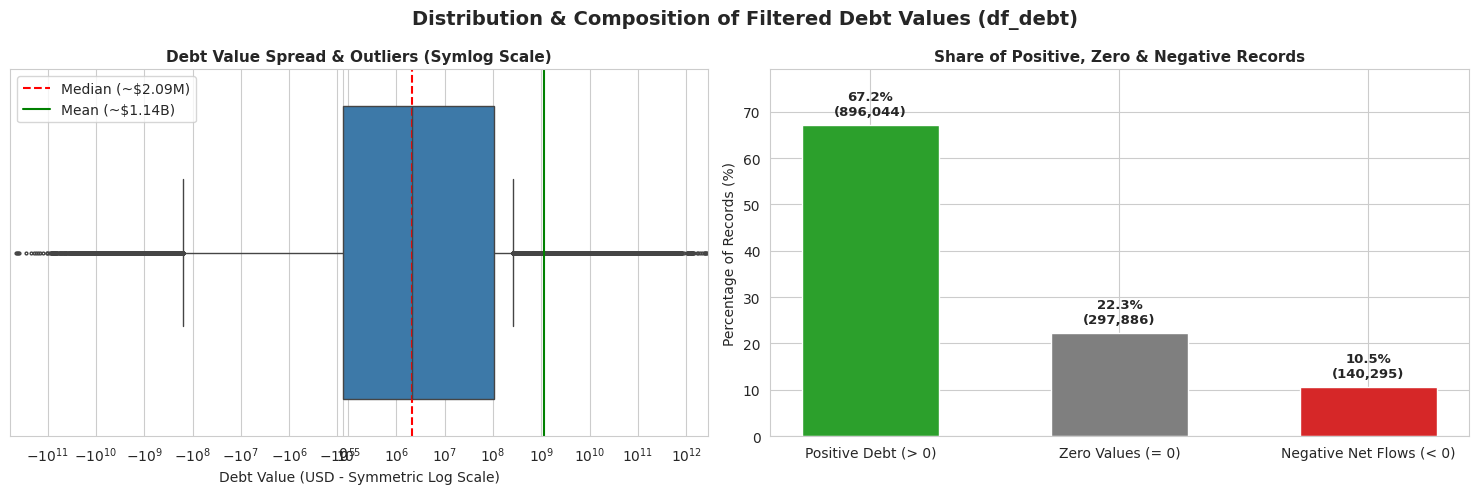

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a 1-row, 2-column figure
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Distribution & Composition of Filtered Debt Values (df_debt)', fontsize=14, fontweight='bold')

# --- Chart 1: Boxplot (Symlog scale to handle negative, zero & trillion values) ---
sns.boxplot(x=df_debt['Debt_Value'], ax=axes[0], color='#2b7bba', fliersize=2)
axes[0].set_xscale('symlog', linthresh=1e6)
axes[0].axvline(df_debt['Debt_Value'].median(), color='red', linestyle='--', linewidth=1.5, label='Median (~$2.09M)')
axes[0].axvline(df_debt['Debt_Value'].mean(), color='green', linestyle='-', linewidth=1.5, label='Mean (~$1.14B)')
axes[0].set_title('Debt Value Spread & Outliers (Symlog Scale)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Debt Value (USD - Symmetric Log Scale)')
axes[0].legend()

# --- Chart 2: Positive vs Zero vs Negative Records Breakdown ---
categories = ['Positive Debt (> 0)', 'Zero Values (= 0)', 'Negative Net Flows (< 0)']
counts = [
    (df_debt['Debt_Value'] > 0).sum(),
    (df_debt['Debt_Value'] == 0).sum(),
    (df_debt['Debt_Value'] < 0).sum()
]
percentages = [(c / len(df_debt)) * 100 for c in counts]

bars = axes[1].bar(categories, percentages, color=['#2ca02c', '#7f7f7f', '#d62728'], width=0.55)
axes[1].set_title('Share of Positive, Zero & Negative Records', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Percentage of Records (%)')
axes[1].set_ylim(0, max(percentages) + 12)

# Add percentage labels on top of bars
for bar, pct, cnt in zip(bars, percentages, counts):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.5,
        f'{pct:.1f}%\n({cnt:,})',
        ha='center', va='bottom', fontsize=9.5, fontweight='bold'
    )

plt.tight_layout()
plt.show()

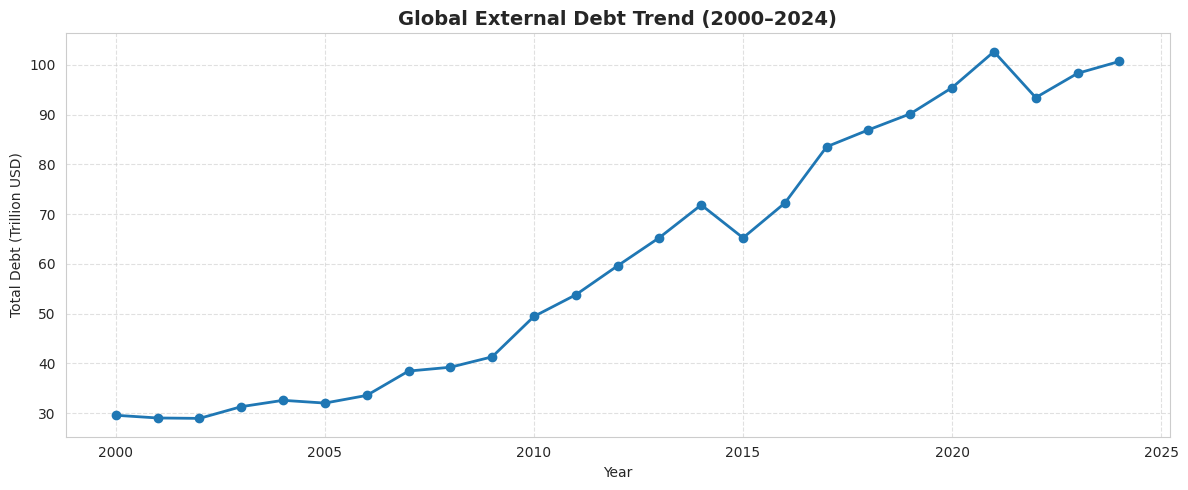

In [18]:
yearly_debt = df_debt.groupby('Year')['Debt_Value'].sum().reset_index()

plt.figure(figsize=(12, 5))
plt.plot(yearly_debt['Year'], yearly_debt['Debt_Value'] / 1e12, marker='o', linewidth=2, color='#1f77b4')
plt.title("Global External Debt Trend (2000–2024)", fontsize=14, fontweight='bold')
plt.xlabel("Year")
plt.ylabel("Total Debt (Trillion USD)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

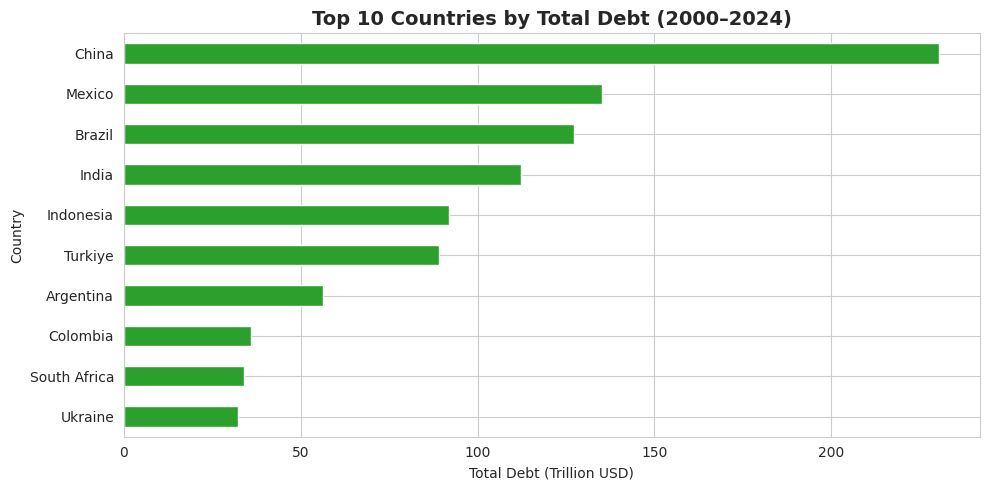

In [19]:
top10_countries = (
    df_debt.groupby('Country_Name')['Debt_Value']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))
(top10_countries / 1e12).plot(kind='barh', color='#2ca02c')
plt.gca().invert_yaxis()
plt.title("Top 10 Countries by Total Debt (2000–2024)", fontsize=14, fontweight='bold')
plt.xlabel("Total Debt (Trillion USD)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

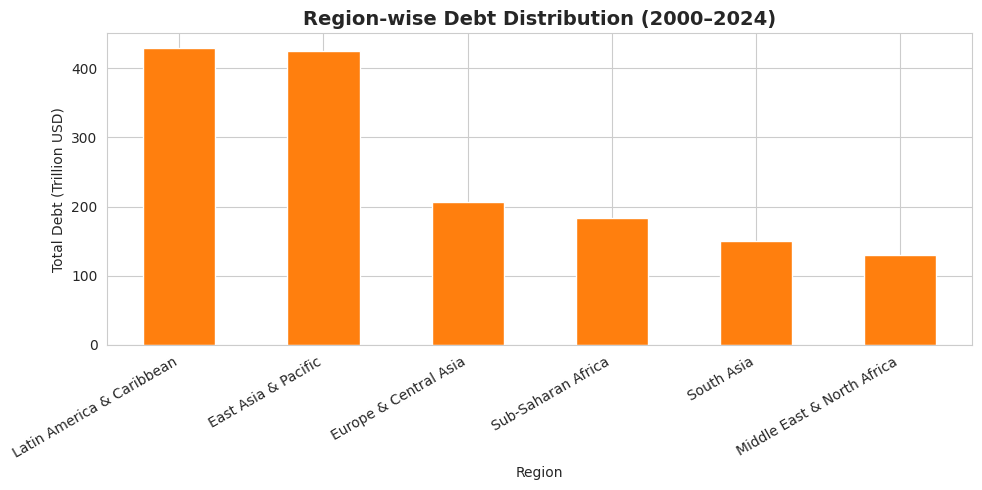

In [20]:
region_debt = (
    df_debt.groupby('Region')['Debt_Value']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
(region_debt / 1e12).plot(kind='bar', color='#ff7f0e')
plt.title("Region-wise Debt Distribution (2000–2024)", fontsize=14, fontweight='bold')
plt.xlabel("Region")
plt.ylabel("Total Debt (Trillion USD)")
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

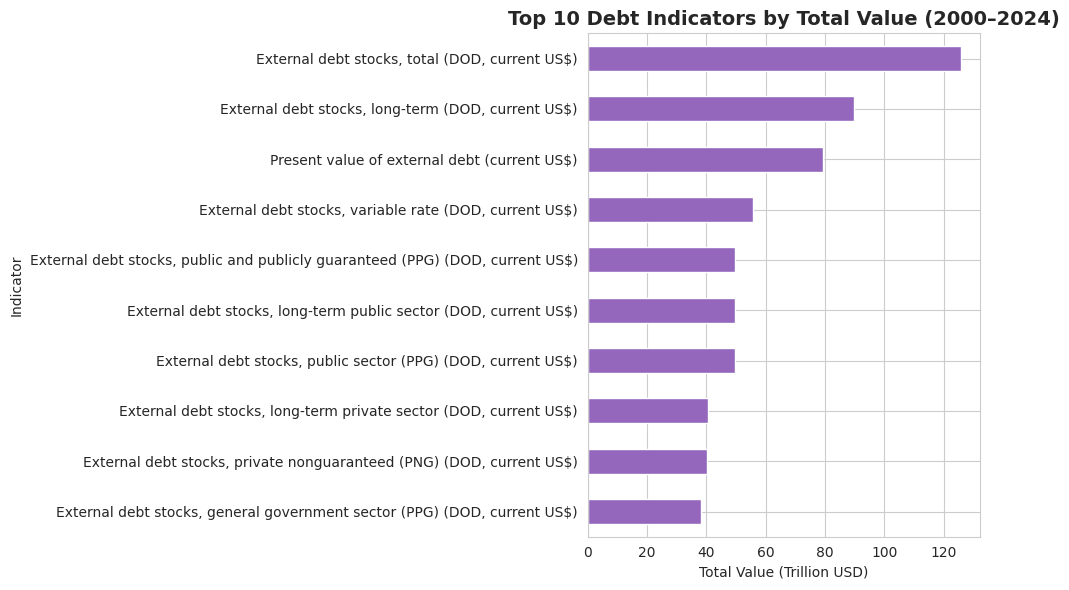

In [21]:
top10_indicators = (
    df_debt.groupby('Series_Name')['Debt_Value']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
(top10_indicators / 1e12).plot(kind='barh', color='#9467bd')
plt.gca().invert_yaxis()
plt.title("Top 10 Debt Indicators by Total Value (2000–2024)", fontsize=14, fontweight='bold')
plt.xlabel("Total Value (Trillion USD)")
plt.ylabel("Indicator")
plt.tight_layout()
plt.show()

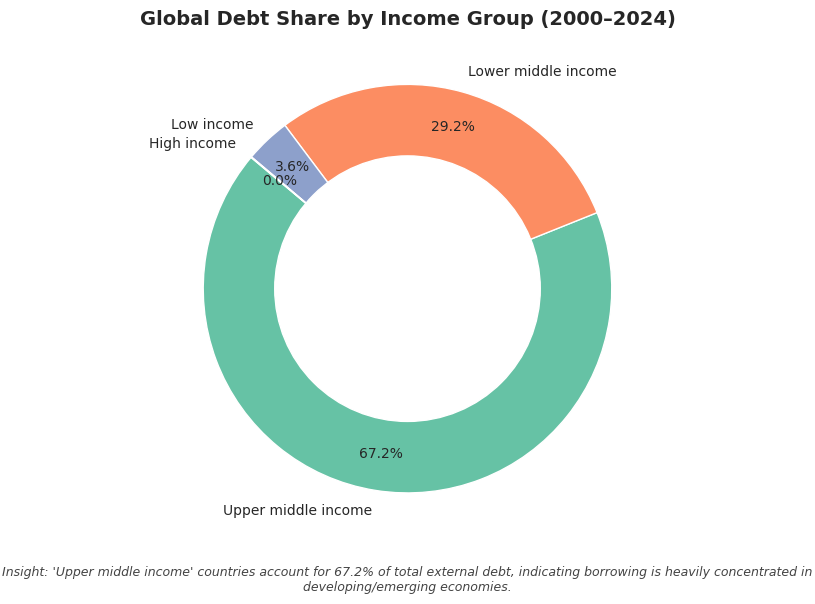

In [22]:
income_debt = (
    df_debt.groupby('Income_Group')['Debt_Value']
    .sum()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 6))
wedges, texts, autotexts = ax.pie(
    income_debt,
    labels=income_debt.index,
    autopct='%1.1f%%',
    startangle=140,
    pctdistance=0.82,
    colors=sns.color_palette("Set2", len(income_debt))
)

# Make it a Donut Chart
centre_circle = plt.Circle((0, 0), 0.65, fc='white')
fig.gca().add_artist(centre_circle)

plt.title("Global Debt Share by Income Group (2000–2024)", fontsize=14, fontweight='bold')

# Insight below visualization in small letters
top_group = income_debt.index[0]
top_pct = (income_debt.iloc[0] / income_debt.sum()) * 100
plt.figtext(
    0.5, 0.01,
    f"Insight: '{top_group}' countries account for {top_pct:.1f}% of total external debt, indicating borrowing is heavily concentrated in developing/emerging economies.",
    ha="center", fontsize=9, style="italic", color="#444444", wrap=True
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

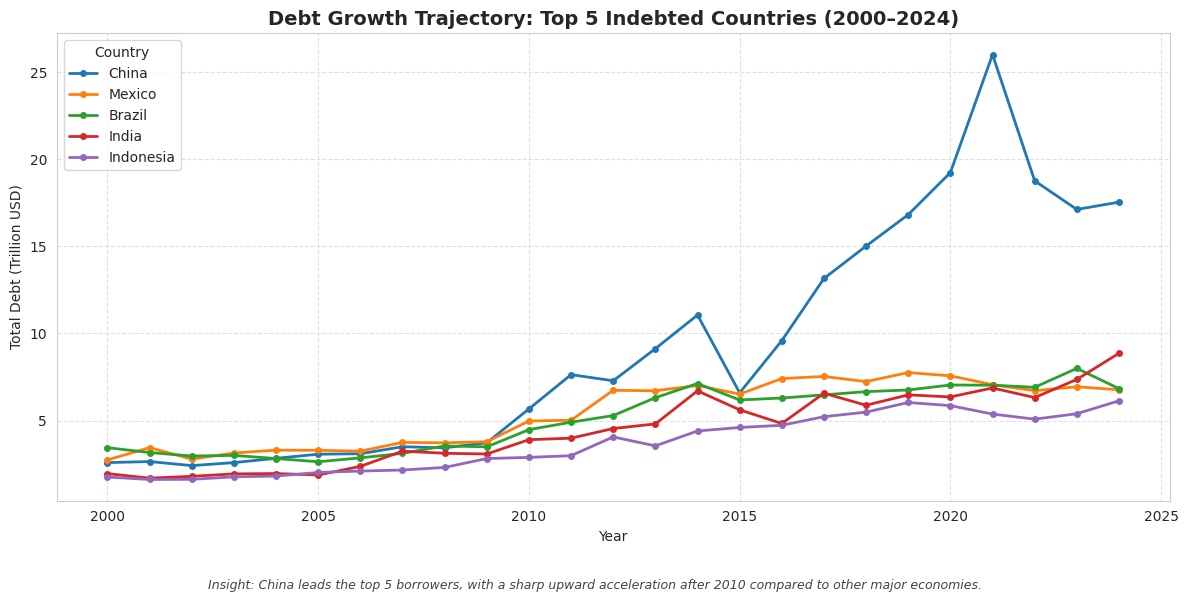

In [23]:
top5_names = (
    df_debt.groupby('Country_Name')['Debt_Value']
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .index
)

top5_trend = (
    df_debt[df_debt['Country_Name'].isin(top5_names)]
    .groupby(['Year', 'Country_Name'])['Debt_Value']
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 6))
for country in top5_names:
    subset = top5_trend[top5_trend['Country_Name'] == country]
    plt.plot(subset['Year'], subset['Debt_Value'] / 1e12, marker='o', markersize=4, linewidth=2, label=country)

plt.title("Debt Growth Trajectory: Top 5 Indebted Countries (2000–2024)", fontsize=14, fontweight='bold')
plt.xlabel("Year")
plt.ylabel("Total Debt (Trillion USD)")
plt.legend(title="Country", loc="upper left")
plt.grid(True, linestyle='--', alpha=0.6)

# Insight below visualization in small letters
plt.figtext(
    0.5, 0.01,
    f"Insight: {top5_names[0]} leads the top 5 borrowers, with a sharp upward acceleration after 2010 compared to other major economies.",
    ha="center", fontsize=9, style="italic", color="#444444", wrap=True
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

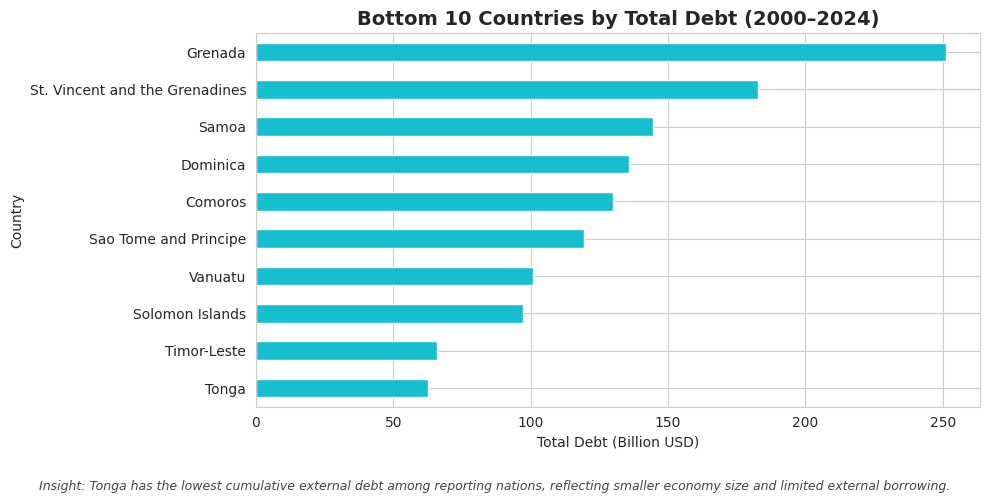

In [24]:
country_totals = df_debt.groupby('Country_Name')['Debt_Value'].sum()
bottom10_countries = country_totals[country_totals > 0].sort_values(ascending=True).head(10)

plt.figure(figsize=(10, 5))
(bottom10_countries / 1e9).plot(kind='barh', color='#17becf')
plt.title("Bottom 10 Countries by Total Debt (2000–2024)", fontsize=14, fontweight='bold')
plt.xlabel("Total Debt (Billion USD)")
plt.ylabel("Country")

# Insight below visualization in small letters
plt.figtext(
    0.5, 0.01,
    f"Insight: {bottom10_countries.index[0]} has the lowest cumulative external debt among reporting nations, reflecting smaller economy size and limited external borrowing.",
    ha="center", fontsize=9, style="italic", color="#444444", wrap=True
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

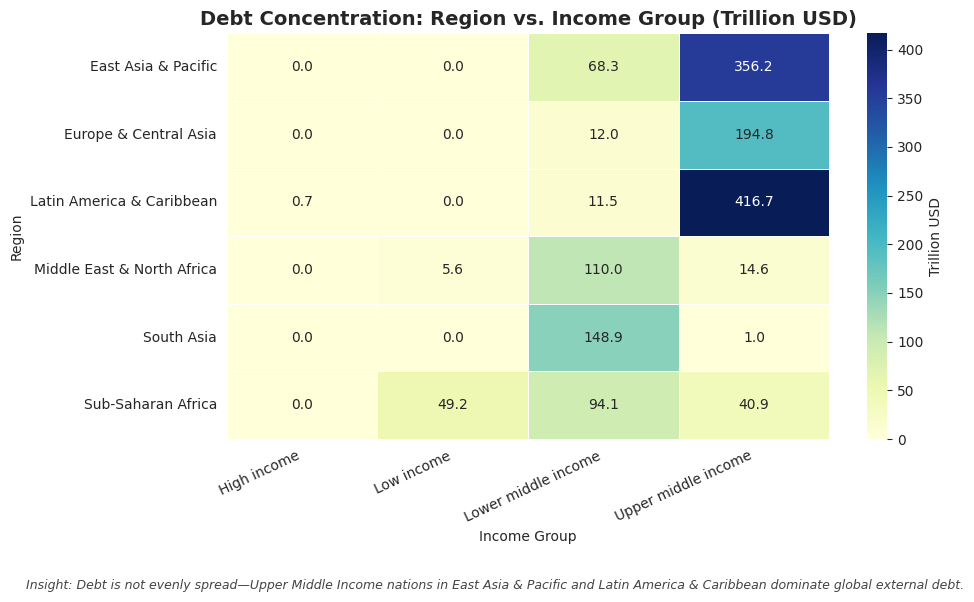

In [25]:
pivot_table = df_debt.pivot_table(
    values='Debt_Value',
    index='Region',
    columns='Income_Group',
    aggfunc='sum',
    fill_value=0
) / 1e12  # Convert to Trillion USD

plt.figure(figsize=(10, 6))
sns.heatmap(pivot_table, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.5, cbar_kws={'label': 'Trillion USD'})
plt.title("Debt Concentration: Region vs. Income Group (Trillion USD)", fontsize=14, fontweight='bold')
plt.xlabel("Income Group")
plt.ylabel("Region")
plt.xticks(rotation=25, ha='right')

# Insight below visualization in small letters
plt.figtext(
    0.5, 0.01,
    "Insight: Debt is not evenly spread—Upper Middle Income nations in East Asia & Pacific and Latin America & Caribbean dominate global external debt.",
    ha="center", fontsize=9, style="italic", color="#444444", wrap=True
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()